# Two PyTorch pendulum examples: data only and physics informed

**Goal:** Predict a pendulum's angle from time using the same 39 noisy measurements in two ways. The first neural network learns only from the measurements. The second also learns from the pendulum equation.

We use an undamped pendulum of length $L=1$ m under gravity $g=9.81$ m/s²:

$$\frac{d^2\theta}{dt^2}+\frac{g}{L}\sin(\theta)=0.$$

The starting angle is $0.6$ rad and the starting angular velocity is zero. The 6.5-second interval covers more than three complete oscillations. Time $t$ is the network input; angle $\theta(t)$ is its output. Run the cells from top to bottom. The clean numerical solution is used to make the sample data and to evaluate predictions; neither network trains on that clean curve.


## 1. Create noisy pendulum measurements

`solve_ivp` produces a clean reference trajectory. We sample it at 39 times and add random measurement noise. A fixed seed makes the notebook reproducible. The companion `pendulum_measurements.csv` contains these same noisy observations for reuse.


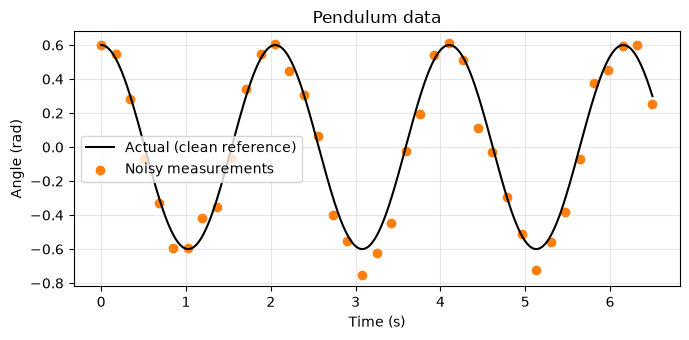

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from scipy.integrate import solve_ivp

torch.set_num_threads(1)  # These tiny networks train efficiently on one CPU thread.
g, L = 9.81, 1.0
theta_0, velocity_0 = 0.6, 0.0
end_time = 6.5

def pendulum(t, state):
    # state contains angle and angular velocity.
    return [state[1], -(g / L) * np.sin(state[0])]

t_plot = np.linspace(0, end_time, 651)
solution = solve_ivp(
    pendulum, (0, end_time), [theta_0, velocity_0],
    t_eval=t_plot, rtol=1e-10, atol=1e-10
)
theta_true = solution.y[0]

sample_indices = np.linspace(0, len(t_plot) - 1, 39, dtype=int)
t_obs = t_plot[sample_indices]
theta_obs = theta_true[sample_indices] + np.random.default_rng(7).normal(0, 0.08, 39)

# PyTorch expects one row per observation and one column per input/output.
t_data = torch.tensor(t_obs[:, None], dtype=torch.float32)
theta_data = torch.tensor(theta_obs[:, None], dtype=torch.float32)

plt.figure(figsize=(7, 3.5))
plt.plot(t_plot, theta_true, "k-", label="Actual (clean reference)")
plt.scatter(t_obs, theta_obs, color="tab:orange", label="Noisy measurements")
plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.title("Pendulum data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 2. Example 1: ordinary supervised learning

This small network maps time to angle. Its loss is the mean squared difference between its predictions and the noisy measured angles. It never sees the pendulum equation. Each update uses all 39 measurements, so the gradients are full-batch. We use a small learning rate to keep the training curve steady.


In [2]:
torch.manual_seed(10)
data_net = nn.Sequential(
    nn.Linear(1, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 1)
)
data_optimizer = torch.optim.Adam(data_net.parameters(), lr=0.001)
epochs = 8000
data_losses = []

for epoch in range(epochs):
    data_optimizer.zero_grad()
    # Use all measurements for this full-batch update.
    predicted_angles = data_net(t_data)
    loss = torch.mean((predicted_angles - theta_data) ** 2)
    loss.backward()
    data_optimizer.step()
    data_losses.append(loss.item())


## 3. Example 2: physics-informed neural network (PINN)

The PINN has the **same architecture and starting weights**. It still fits the noisy measurements, but its loss also penalizes violations of the pendulum equation at 201 times across the interval. PyTorch automatic differentiation supplies the first and second time derivatives.

The physics residual is $r(t)=\frac{L}{g}\,\theta''_{\mathrm{net}}(t)+\sin(\theta_{\mathrm{net}}(t))$. Multiplying the equation by $L/g$ puts this residual on roughly the same scale as the angle errors. The total loss is **data loss + physics loss**, with equal weights for this example. Each update uses all 39 measurements and all 201 physics times. Mini-batches would introduce sampling noise; with this small dataset, full-batch updates make the comparison easier to interpret.


In [3]:
torch.manual_seed(10)  # Start with the same weights as the data-only network.
pinn = nn.Sequential(
    nn.Linear(1, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 1)
)
pinn_optimizer = torch.optim.Adam(pinn.parameters(), lr=0.001)
t_physics = torch.linspace(0, end_time, 201).reshape(-1, 1).requires_grad_(True)
pinn_losses = []

for epoch in range(epochs):
    pinn_optimizer.zero_grad()

    # Fit all noisy observations used by the first network.
    data_loss = torch.mean((pinn(t_data) - theta_data) ** 2)

    # Evaluate all physics times and differentiate with respect to time.
    theta_physics = pinn(t_physics)
    theta_t = torch.autograd.grad(
        theta_physics, t_physics, torch.ones_like(theta_physics), create_graph=True
    )[0]
    theta_tt = torch.autograd.grad(
        theta_t, t_physics, torch.ones_like(theta_t), create_graph=True
    )[0]
    residual = theta_tt / (g / L) + torch.sin(theta_physics)
    physics_loss = torch.mean(residual ** 2)

    loss = data_loss + physics_loss
    loss.backward()
    pinn_optimizer.step()
    pinn_losses.append(loss.item())


## 4. Compare predictions and training losses

The top row compares each network with the clean reference and noisy measurements. The bottom row shows the loss minimized by each network at every epoch; the logarithmic vertical scale makes the later changes visible. The two loss values are **different quantities**: the PINN curve includes a physics penalty, so compare prediction quality in the top row rather than comparing the final loss numbers directly.


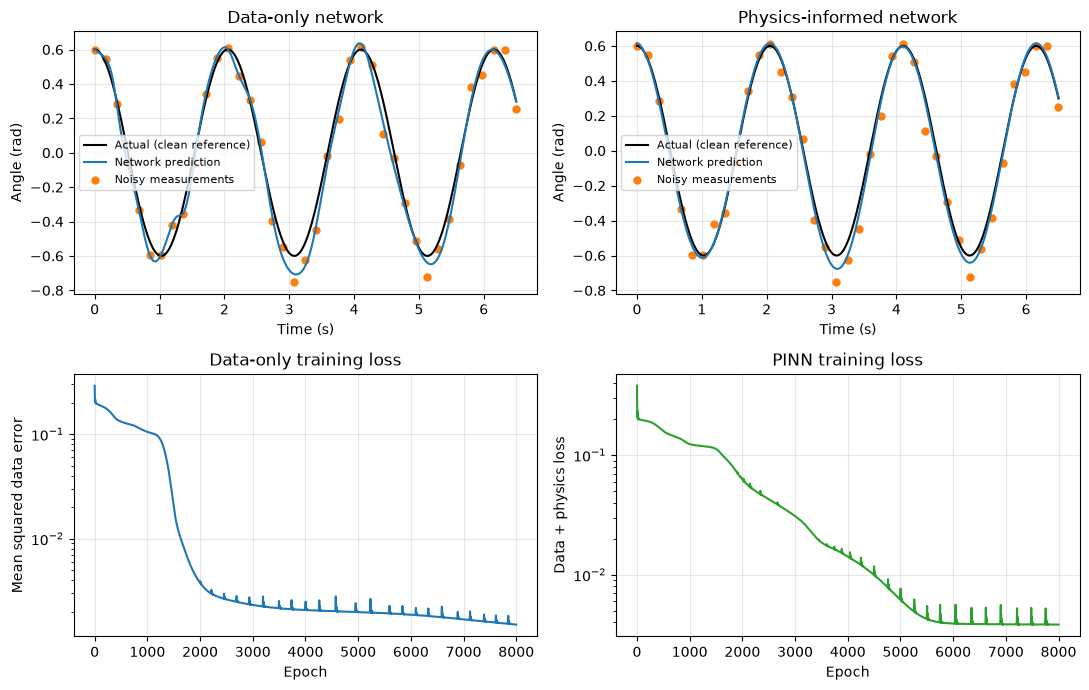

Data-only RMSE against clean reference: 0.062 rad
PINN RMSE against clean reference:      0.033 rad


In [4]:
with torch.no_grad():
    t_dense = torch.tensor(t_plot[:, None], dtype=torch.float32)
    data_prediction = data_net(t_dense).numpy().ravel()
    pinn_prediction = pinn(t_dense).numpy().ravel()

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, prediction, title in zip(
    axes[0], [data_prediction, pinn_prediction], ["Data-only network", "Physics-informed network"]
):
    ax.plot(t_plot, theta_true, "k-", label="Actual (clean reference)")
    ax.plot(t_plot, prediction, color="tab:blue", label="Network prediction")
    ax.scatter(t_obs, theta_obs, color="tab:orange", s=25, label="Noisy measurements")
    ax.set(title=title, xlabel="Time (s)", ylabel="Angle (rad)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[1, 0].semilogy(data_losses, color="tab:blue")
axes[1, 0].set(title="Data-only training loss", xlabel="Epoch", ylabel="Mean squared data error")
axes[1, 1].semilogy(pinn_losses, color="tab:green")
axes[1, 1].set(title="PINN training loss", xlabel="Epoch", ylabel="Data + physics loss")
for ax in axes[1]:
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

# These errors use the clean reference only for evaluation, never for training.
data_rmse = np.sqrt(np.mean((data_prediction - theta_true) ** 2))
pinn_rmse = np.sqrt(np.mean((pinn_prediction - theta_true) ** 2))
print(f"Data-only RMSE against clean reference: {data_rmse:.3f} rad")
print(f"PINN RMSE against clean reference:      {pinn_rmse:.3f} rad")
